<a href="https://colab.research.google.com/github/stephanie-rmz/Anal-tica-de-datos/blob/main/UNIDAD2/Actividad2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**INSTITUTO TECNOLOGICO DE CIUDAD JUAREZ**

**Ciencia y analítica de datos**

MODELOS DE APRENDIZAJE


**ACTIVIDAD 2**
Exploración de datos

---

*   NOMBRE: Stephanie Y. Ramirez Saucedo
*   NO. CONTROL: 22111457

-------

# CODIGO PARA ACCEDER A NUESTRO DRIVE

In [18]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [19]:
import pandas as pd

ruta_archivo = '/content/drive/MyDrive/Colab Notebooks/credit_risk_dataset.csv'
df = pd.read_csv(ruta_archivo)

#df.head()

# IMPORTA LAS LIBRERIAS NECESARIAS

In [20]:
# libreria manipulacion de datos
import pandas as pd

# libreria para calculos numericos y estadisticos
import numpy as np

# Librerias para graficar
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")





# CONVIERTE ARCHIVO CSV A TIPO DataFrame (df)

In [21]:

df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/credit_risk_dataset.csv')
#df.head()

----

# **Parte 1**. Análisis descriptivo (univariante)

1. Utiliza el método `info()` del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas cualitativas?

<font color="orange">ESCRIBE AQUI TU RESPUESTA</FONT>

8 columnas numéricas (5 de tipo entero int64: person_age, person_income, loan_amnt, loan_status, cb_person_cred_hist_length; y 3 de tipo decimal float64: person_emp_length, loan_int_rate, loan_percent_income).

4 columnas cualitativas/categóricas (tipo object: person_home_ownership, loan_intent, loan_grade, cb_person_default_on_file).

In [22]:
#.info()muestra la informacion del dataframe numero de columnas y del tipo de dato de cada una de las columnas
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB


 2. Determina el porcentaje de valores faltantes por columna.

In [23]:
# .isna() revisa si existen valores nulos y .mean() calcula el porcentaje promedio
porcentaje_nulos = (df.isna().mean() * 100).round(3)
print("Porcentaje de valores faltantes por columna (%):")
print(porcentaje_nulos[porcentaje_nulos > 0])

Porcentaje de valores faltantes por columna (%):
person_emp_length    2.747
loan_int_rate        9.564
dtype: float64


----

# Análisis de variables numéricas

3. Obtén las siguientes estadísticas descriptivas para todas las variables numéricas:
*   Tendencia central (media, mediana)
*   Dispersión o variabilidad (min, max, desviación estándar, cuartiles)
*   Forma (asimetría y curtosis)
*   Clasifica las variables `person_age` y `loan_in_rate` según los valores observados de asimetría y curtosis

**NOTA**. Recuerda que muchas de estas estadísticas, puedes obtenerlas utilizando la función `describe()` y que la mediana está representada en el 2do cuartil (50%)

#

In [24]:
# Estadísticas descriptivas (tendencia central y dispersión)
print("--- Estadísticas Descriptivas ---")
display(df[['person_age', 'loan_int_rate', 'loan_percent_income']].describe())

# Asimetría (Skewness)
print("\n--- Asimetría (Skewness) ---")
print(df[['person_age', 'loan_int_rate', 'loan_percent_income']].skew())

# Curtosis
print("\n--- Curtosis ---")
print(df[['person_age', 'loan_int_rate', 'loan_percent_income']].kurtosis())

--- Estadísticas Descriptivas ---


,person_age,loan_int_rate,loan_percent_income
count,32581.000000,29465.000000,32581.000000
mean,27.734600,11.011695,0.170203
std,6.348078,3.240459,0.106782
min,20.000000,5.420000,0.000000
25%,23.000000,7.900000,0.090000
50%,26.000000,10.990000,0.150000
75%,30.000000,13.470000,0.230000
max,144.000000,23.220000,0.830000



--- Asimetría (Skewness) ---
person_age             2.581393
loan_int_rate          0.208550
loan_percent_income    1.064669
dtype: float64

--- Curtosis ---
person_age             18.560825
loan_int_rate          -0.671609
loan_percent_income     1.223687
dtype: float64


------

4. Utiliza histogramas para determinar la distribución de los valores representados en cada variable.
*   ¿Se corresponde con lo obtenido en el cálculo de asimetría? Como verás, los datos reales son más complejos que la teoría. Por esta razón, recuerda siempre acompañar el análisis de la asimetría con algún gráfico como un histograma.

**NOTA**. Para esto también puedes ocupar los gráficos `kde` ([kernel density estimation](https://www.cienciadedatos.net/documentos/pystats02-kernel-density-estimation-kde-python.html)) que crean una curva continua y suave expandiendo la idea del histograma.

<font color="orange">AGREGA LA RESPUESTA A LA PREGUNTA AQUI</FONT>

Sí, los histogramas y las curvas KDE visualizan perfectamente lo calculado: person_age muestra una concentración fuerte al inicio con una cola larga hacia la derecha (asimetría positiva), mientras que loan_int_rate se ve mucho más equilibrada y simétrica.

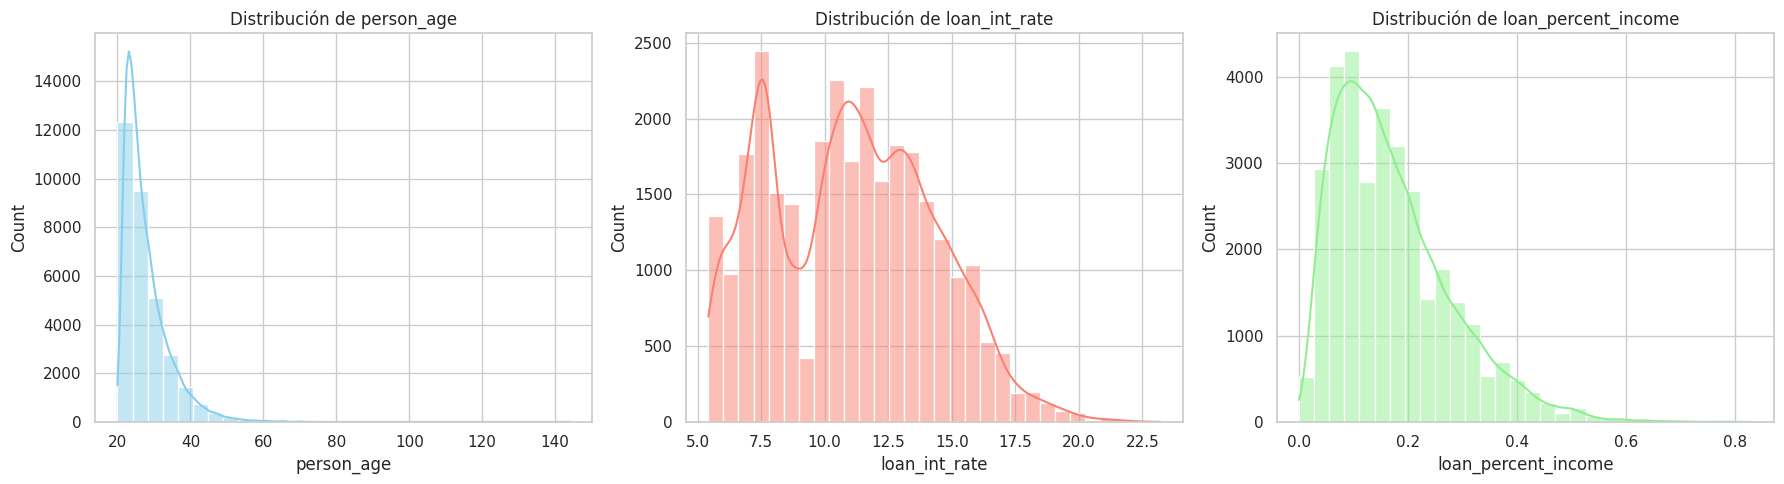

In [25]:
# Configuración de los histogramas y curvas KDE para las variables numéricas principales
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(df['person_age'], kde=True, ax=axes[0], color='skyblue', bins=30)
axes[0].set_title('Distribución de person_age')

sns.histplot(df['loan_int_rate'].dropna(), kde=True, ax=axes[1], color='salmon', bins=30)
axes[1].set_title('Distribución de loan_int_rate')

sns.histplot(df['loan_percent_income'], kde=True, ax=axes[2], color='lightgreen', bins=30)
axes[2].set_title('Distribución de loan_percent_income')

plt.tight_layout()
plt.show()

----

5. Emplea boxplots para mostrar la distribución de los datos a través de sus cuartiles.

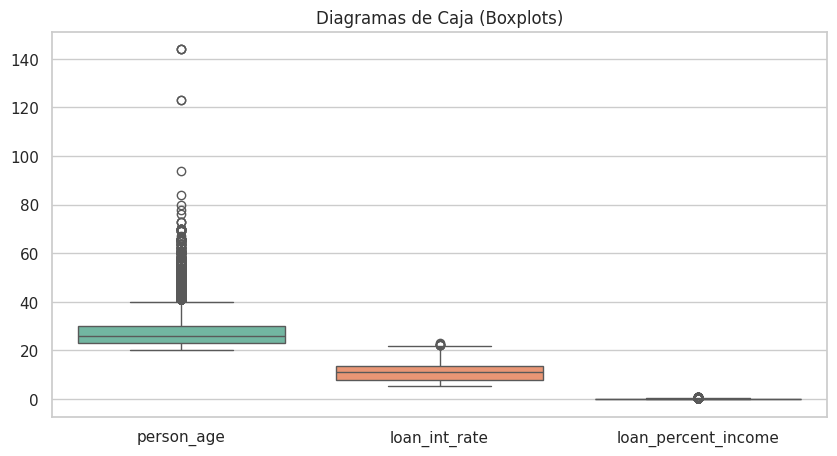

In [26]:
# Boxplots generales para las variables numéricas
plt.figure(figsize=(10, 5))
sns.boxplot(data=df[['person_age', 'loan_int_rate', 'loan_percent_income']], palette='Set2')
plt.title('Diagramas de Caja (Boxplots)')
plt.show()

-----

*   Como podrás observar hay valores atípicos en todas las variables. Ejecuta el siguiente código para identificar los valores atípicos en la variable `person_age`

**Interpretación Resultados**

<FONT COLOR="ORANGE">AGREGA AQUI LA INTERPRETACION DE TUS RESULTADOS</FONT>

El análisis mediante diagramas de caja (boxplots) permite identificar la presencia de valores atípicos (outliers) en todas las variables numéricas. Por ejemplo, en person_age se detectan edades extremas poco frecuentes o erróneas (como 144 años), las cuales se ubican muy por encima del límite superior calculado mediante el rango intercuartílico  

In [27]:
# Obtiene el primer cuartil (percentil 25) de la columna 'person_age'
percentile_25 = df["person_age"].quantile(0.25)

# Obtiene el tercer cuartil (percentil 75) de la columna 'person_age'
percentile_75 = df["person_age"].quantile(0.75)

# Calcula el Rango Intercuartílico (IQR) restando el percentil 25 al 75
iqr = percentile_75 - percentile_25

# Define el límite superior para identificar valores atípicos (outliers)
upper_limit = percentile_75 + 1.5 * iqr

# Define el límite inferior para identificar valores atípicos (outliers)
lower_limit = percentile_25 - 1.5 * iqr

# Filtra el DataFrame para obtener las filas donde la edad esté fuera de los límites calculados
IQR_outliers = df[(df["person_age"] < lower_limit) | (df["person_age"] > upper_limit)]

# Muestra el DataFrame resultante que contiene únicamente los valores atípicos detectados
IQR_outliers

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
81,144,250000,RENT,4.0,VENTURE,C,4800,13.57,0,0.02,N,3
183,144,200000,MORTGAGE,4.0,EDUCATION,B,6000,11.86,0,0.03,N,2
575,123,80004,RENT,2.0,EDUCATION,B,20400,10.25,0,0.25,N,3
747,123,78000,RENT,7.0,VENTURE,B,20000,NaN,0,0.26,N,4
29121,50,900000,MORTGAGE,11.0,DEBTCONSOLIDATION,B,30000,12.69,0,0.03,N,15
...,...,...,...,...,...,...,...,...,...,...,...,...
32576,57,53000,MORTGAGE,1.0,PERSONAL,C,5800,13.16,0,0.11,N,30
32577,54,120000,MORTGAGE,4.0,PERSONAL,A,17625,7.49,0,0.15,N,19
32578,65,76000,RENT,3.0,HOMEIMPROVEMENT,B,35000,10.99,1,0.46,N,28
32579,56,150000,MORTGAGE,5.0,PERSONAL,B,15000,11.48,0,0.10,N,26


In [28]:
# Identificación de valores atípicos en person_age usando IQR
percentile_25 = df["person_age"].quantile(0.25)
percentile_75 = df["person_age"].quantile(0.75)

iqr = percentile_75 - percentile_25

upper_limit = percentile_75 + 1.5 * iqr
lower_limit = percentile_25 - 1.5 * iqr

IQR_outliers = df[(df["person_age"] < lower_limit) | (df["person_age"] > upper_limit)]
print(f"Total de valores atípicos detectados en person_age: {len(IQR_outliers)}")
display(IQR_outliers.head())

Total de valores atípicos detectados en person_age: 1494


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
81,144,250000,RENT,4.0,VENTURE,C,4800,13.57,0,0.02,N,3
183,144,200000,MORTGAGE,4.0,EDUCATION,B,6000,11.86,0,0.03,N,2
575,123,80004,RENT,2.0,EDUCATION,B,20400,10.25,0,0.25,N,3
747,123,78000,RENT,7.0,VENTURE,B,20000,NaN,0,0.26,N,4
29121,50,900000,MORTGAGE,11.0,DEBTCONSOLIDATION,B,30000,12.69,0,0.03,N,15


-----

# Análisis de variables de texto

 6. Obtén las siguientes estadísticas descriptivas para todas las variables de texto:
*   Tendencia central (moda)
*   Cardinalidad (cantidad de valores únicos)
*   Recuentos únicos (número de ocurrencias para cada valor único)

**NOTA**. Un resumen de estas estadísticas, puedes obtenerlas indicando en la función `describe()` que se incluirán sólo las variables de tipo object: `describe(include = 'object')`. Para los recuentos utiliza la función `df['columna'].value_counts()`

In [29]:
#IDENTIFIQUE CUALES SON LAS VARIABLES DE TEXTO

In [30]:
# Resumen estadístico exclusivo para variables de texto (object)
print("--- Resumen de variables cualitativas ---")
display(df.describe(include='object'))

# Recuentos únicos detallados para cada variable de texto
for col in df.select_dtypes(include=['object']).columns:
    print(f"\nRecuentos para la columna: {col}")
    print(df[col].value_counts())

--- Resumen de variables cualitativas ---


,person_home_ownership,loan_intent,loan_grade,cb_person_default_on_file
count,32581,32581,32581,32581
unique,4,6,7,2
top,RENT,EDUCATION,A,N
freq,16446,6453,10777,26836



Recuentos para la columna: person_home_ownership
person_home_ownership
RENT        16446
MORTGAGE    13444
OWN          2584
OTHER         107
Name: count, dtype: int64

Recuentos para la columna: loan_intent
loan_intent
EDUCATION            6453
MEDICAL              6071
VENTURE              5719
PERSONAL             5521
DEBTCONSOLIDATION    5212
HOMEIMPROVEMENT      3605
Name: count, dtype: int64

Recuentos para la columna: loan_grade
loan_grade
A    10777
B    10451
C     6458
D     3626
E      964
F      241
G       64
Name: count, dtype: int64

Recuentos para la columna: cb_person_default_on_file
cb_person_default_on_file
N    26836
Y     5745
Name: count, dtype: int64


-----

7. Utiliza gráficos de barras por variable para representar la frecuencia de cada categoría.

**NOTA**. seaborn posee un gráfico de recuento, para variables de tipo object, que calcula la frecuencia de cada categoría sin necesidad de utilizar la función `value_counts()`. Para generarlo debes indicar la columna: `sns.countplot(x='columna', data=df) `

/tmp/ipykernel_1109/58286373.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=col, data=df, palette='viridis', order=df[col].value_counts().index)


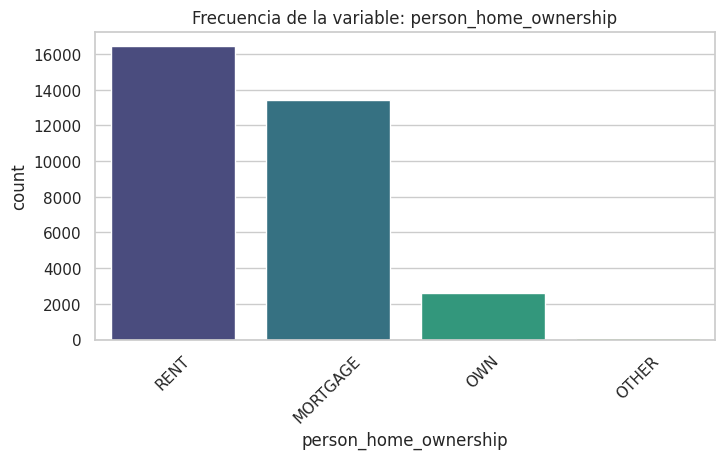

/tmp/ipykernel_1109/58286373.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=col, data=df, palette='viridis', order=df[col].value_counts().index)


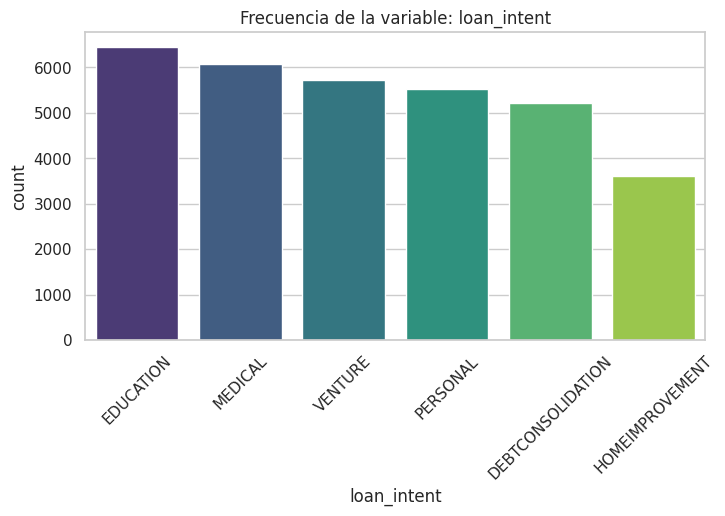

/tmp/ipykernel_1109/58286373.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=col, data=df, palette='viridis', order=df[col].value_counts().index)


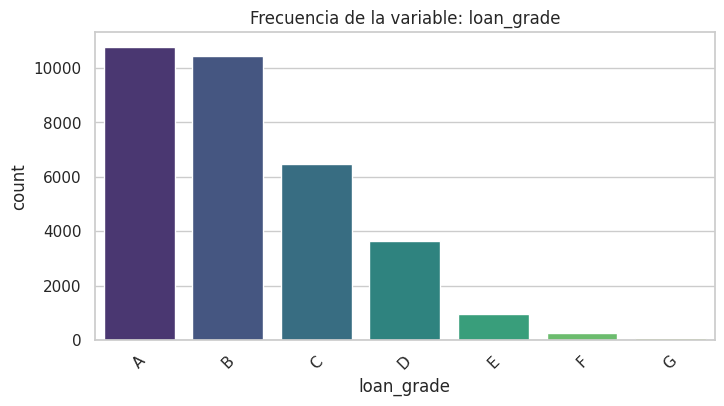

/tmp/ipykernel_1109/58286373.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=col, data=df, palette='viridis', order=df[col].value_counts().index)


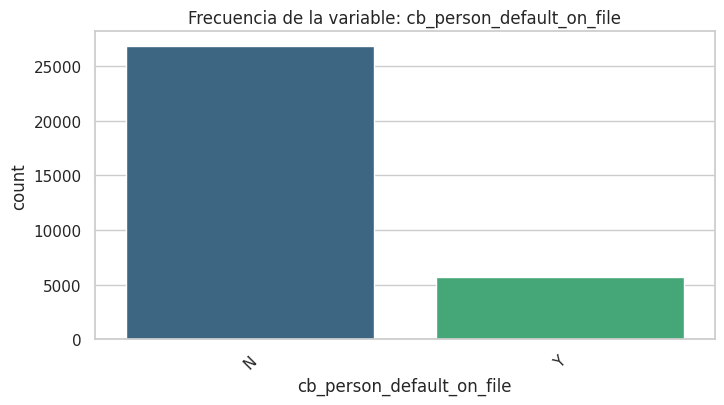

In [31]:
# Gráficos de recuento (countplot) para cada variable cualitativa
cat_cols = df.select_dtypes(include=['object']).columns

for col in cat_cols:
    plt.figure(figsize=(8, 4))
    sns.countplot(x=col, data=df, palette='viridis', order=df[col].value_counts().index)
    plt.title(f'Frecuencia de la variable: {col}')
    plt.xticks(rotation=45)
    plt.show()

-----

# **Parte 2**. Análisis de correlación (bivariante y multivariante)

La variable `loan_status` será la variable de salida (o a predecir en un modelo de ML). Analiza su relación con el resto de las variables a través de los siguientes gráficos:

8. Un box plot para visualizar la distribución de `loan_percent_income` según el `loan_status`. Interpreta el resultado.

/tmp/ipykernel_1109/760620433.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='loan_status', y='loan_percent_income', data=df, palette='Set1')


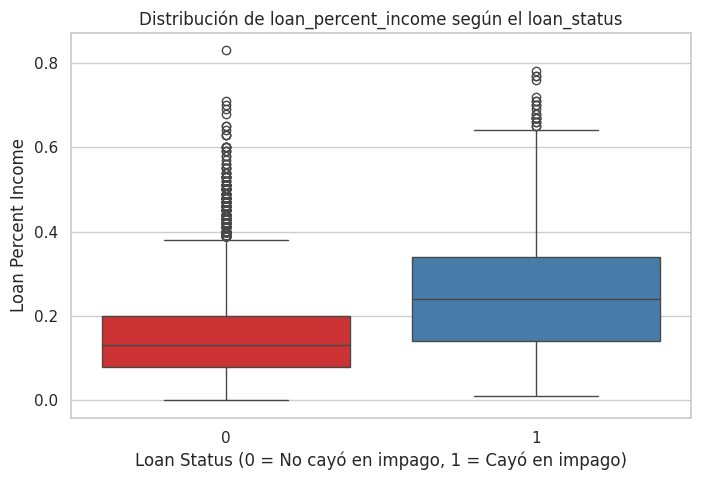

In [32]:
# Box plot para visualizar la distribución de loan_percent_income según el loan_status
plt.figure(figsize=(8, 5))
sns.boxplot(x='loan_status', y='loan_percent_income', data=df, palette='Set1')
plt.title('Distribución de loan_percent_income según el loan_status')
plt.xlabel('Loan Status (0 = No cayó en impago, 1 = Cayó en impago)')
plt.ylabel('Loan Percent Income')
plt.show()

**Interpretación resultados**

<FONT COLOR="ORANGE">AGREGUE AQUI SU RESPUESTA</FONT>

Las personas que cayeron en incumplimiento de pago presentan una mediana y un rango intercuartílico considerablemente más altos en el porcentaje de ingresos destinado al préstamo, lo que demuestra que un mayor peso de la deuda frente a los ingresos incrementa notablemente el riesgo de impago


 9. En los gráficos de barras que obtuviste en el ejercicio 7, separa el conteo según el `load_status`, utilizando el parámetro `hue`.

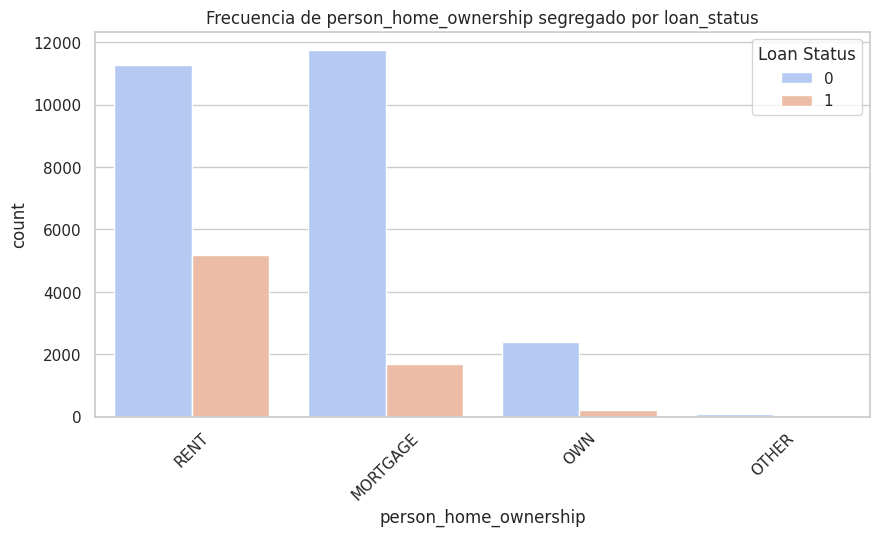

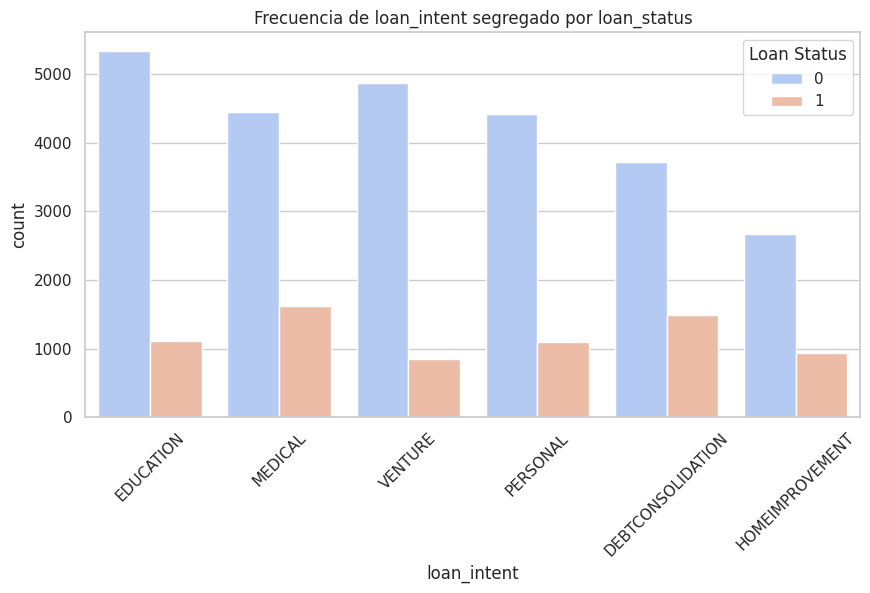

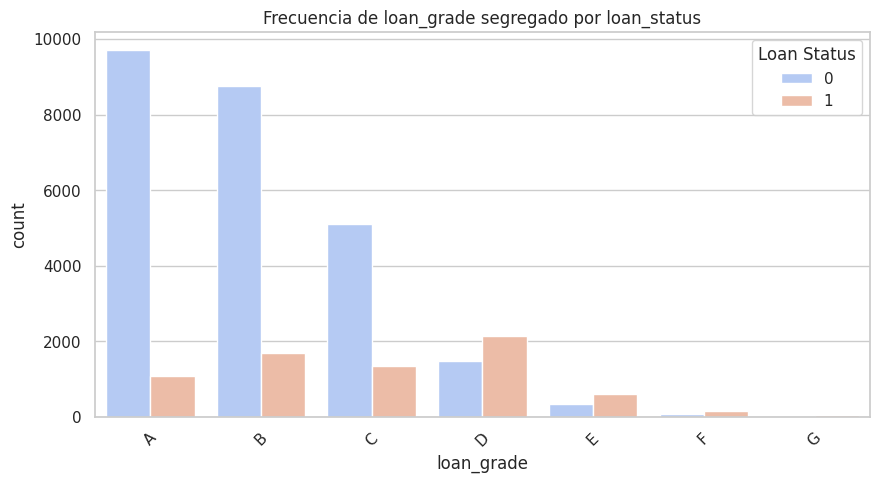

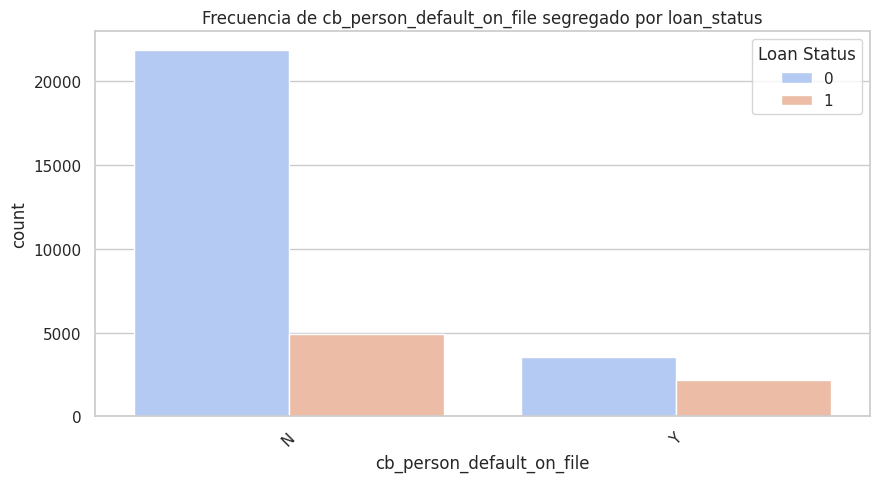

In [33]:
# Gráficos de recuento para variables cualitativas segregados por loan_status
cat_cols = df.select_dtypes(include=['object']).columns

for col in cat_cols:
    plt.figure(figsize=(10, 5))
    sns.countplot(x=col, hue='loan_status', data=df, palette='coolwarm', order=df[col].value_counts().index)
    plt.title(f'Frecuencia de {col} segregado por loan_status')
    plt.xticks(rotation=45)
    plt.legend(title='Loan Status')
    plt.show()

10. Un mapa de calor con los valores de correlación de todas las variables del dataframe.
*   ¿Qué variable tiene mayor correlación con `loan_status`?

**Respuesta a pregunta**

<FONT COLOR="ORANGE">AGREGUE SU RESPUESTA AQUI</FONT>
La variable numérica que presenta mayor correlación con loan_status es loan_percent_income con un valor aproximado de 0.38, seguida de cerca por la tasa de interés loan_int_rate con 0.34



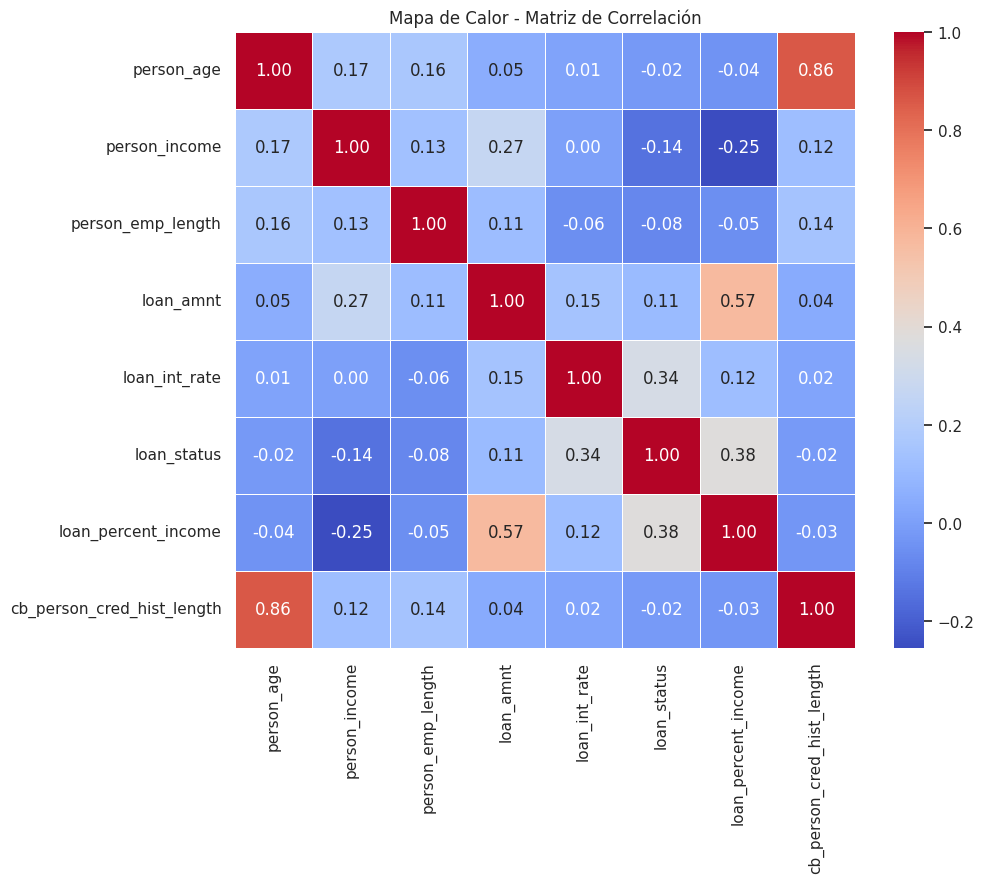


Correlación de las variables con respecto a loan_status:
loan_status                   1.000000
loan_percent_income           0.379366
loan_int_rate                 0.335133
loan_amnt                     0.105376
cb_person_cred_hist_length   -0.015529
person_age                   -0.021629
person_emp_length            -0.082489
person_income                -0.144449
Name: loan_status, dtype: float64


In [34]:
# Mapa de calor con los valores de correlación de todas las variables numéricas
plt.figure(figsize=(10, 8))
correlation_matrix = df.select_dtypes(include=['int64', 'float64']).corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Mapa de Calor - Matriz de Correlación')
plt.show()

# Imprimir las correlaciones específicas con loan_status ordenadas de mayor a menor
print("\nCorrelación de las variables con respecto a loan_status:")
print(correlation_matrix['loan_status'].sort_values(ascending=False))